In [14]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers,models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import os
import time

In [ ]:

tf.random.set_seed(42)
np.random.seed(42)

VOCAB_SIZE = 10000
MAX_LEN = 250
EMBED_DIM = 128
UNITS = 64
BATCH_SIZE = 64

num_words(vocab size):IMDB has about 88,000 different words.We keep only the top 10,000 most common words.

In [15]:
x_train_full = pad_sequences(x_train_full, maxlen=MAX_LEN, padding="post", truncating="post")
x_test = pad_sequences(x_test, maxlen=MAX_LEN, padding="post", truncating="post")

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=0.2, random_state=42, stratify=y_train_full
)

In [21]:
def build_rnn():
    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.SimpleRNN(UNITS),
        layers.Dropout(0.4),
        layers.Dense(1, activation="sigmoid")
    ], name="Simple_RNN")
    return model


def build_lstm():
    model = models.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True),
        layers.LSTM(UNITS),
        layers.Dropout(0.4),
        layers.Dense(1, activation="sigmoid")
    ], name="LSTM")
    return model

In [22]:
rnn_model = build_rnn()
lstm_model = build_lstm()

rnn_model.summary()
lstm_model.summary()

Model: "Simple_RNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 250, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 250, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:

def train_model(model, name, epochs=10):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        ModelCheckpoint(f"models/{name}.keras", monitor="val_loss", save_best_only=True)
    ]
    start = time.time()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        callbacks=callbacks
    )
    return history, time.time() - start

In [26]:
rnn_history, rnn_time = train_model(rnn_model, "simple_rnn")
lstm_history, lstm_time = train_model(lstm_model, "lstm")

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8773 - loss: 0.3041 - val_accuracy: 0.7886 - val_loss: 0.4831
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9201 - loss: 0.2145 - val_accuracy: 0.7602 - val_loss: 0.5620
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9469 - loss: 0.1487 - val_accuracy: 0.7638 - val_loss: 0.6695
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.9272 - loss: 0.2062 - val_accuracy: 0.8304 - val_loss: 0.4400
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.9433 - loss: 0.1624 - val_accuracy: 0.8370 - val_loss: 0.4423
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.9570 - loss: 0.1300 - val_accuracy: 0.8412 - val_loss: 0.4731


In [27]:
print("RNN epochs run:", len(rnn_history.history["loss"]), f"| time: {rnn_time:.1f}s")
print("LSTM epochs run:", len(lstm_history.history["loss"]), f"| time: {lstm_time:.1f}s")

RNN epochs run: 3 | time: 20.8s
LSTM epochs run: 3 | time: 44.9s


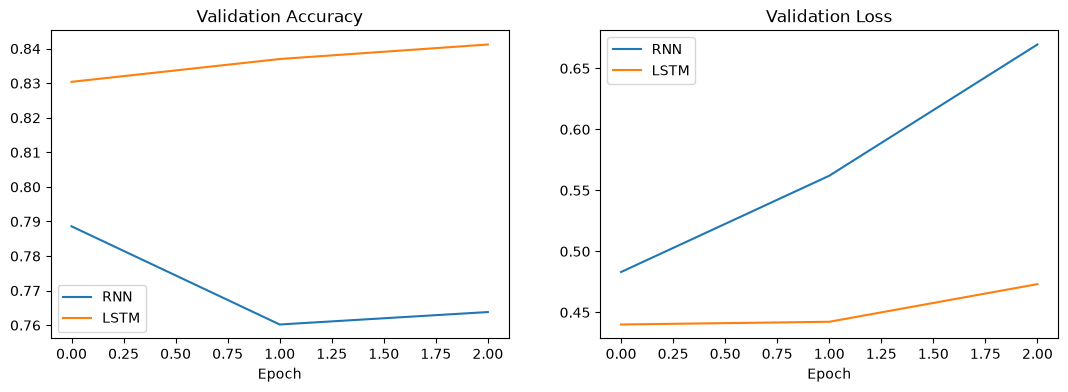

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(rnn_history.history["val_accuracy"], label="RNN")
ax[0].plot(lstm_history.history["val_accuracy"], label="LSTM")
ax[0].set_title("Validation Accuracy")
ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(rnn_history.history["val_loss"], label="RNN")
ax[1].plot(lstm_history.history["val_loss"], label="LSTM")
ax[1].set_title("Validation Loss")
ax[1].set_xlabel("Epoch"); ax[1].legend()

plt.show()

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

def get_predictions(model):
    probs = model.predict(x_test, batch_size=BATCH_SIZE)
    preds = (probs > 0.5).astype(int).ravel()
    return probs.ravel(), preds

rnn_probs, rnn_preds = get_predictions(rnn_model)
lstm_probs, lstm_preds = get_predictions(lstm_model)

print("=== Simple RNN ===")
print(classification_report(y_test, rnn_preds, target_names=["Negative", "Positive"]))
print("=== LSTM ===")
print(classification_report(y_test, lstm_preds, target_names=["Negative", "Positive"]))

391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step
=== Simple RNN ===
              precision    recall  f1-score   support

    Negative       0.75      0.88      0.81     12500
    Positive       0.85      0.70      0.77     12500

    accuracy                           0.79     25000
   macro avg       0.80      0.79      0.79     25000
weighted avg       0.80      0.79      0.79     25000

=== LSTM ===
              precision    recall  f1-score   support

    Negative       0.77      0.92      0.84     12500
    Positive       0.90      0.72      0.80     12500

    accuracy                           0.82     25000
   macro avg       0.84      0.82      0.82     25000
weighted avg       0.84      0.82      0.82     25000



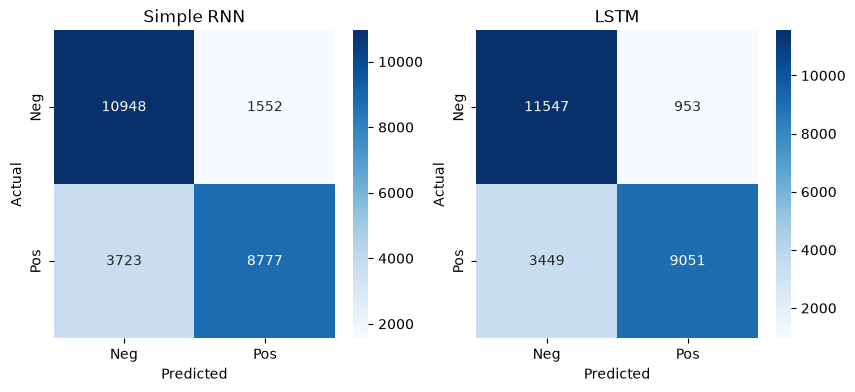

In [30]:
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, preds, name in zip(ax, [rnn_preds, lstm_preds], ["Simple RNN", "LSTM"]):
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt="d",
                cmap="Blues", ax=a,
                xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    a.set_title(name); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.show()

In [31]:
results = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM"],
    "Test Accuracy": [accuracy_score(y_test, rnn_preds), accuracy_score(y_test, lstm_preds)],
    "F1 Score": [f1_score(y_test, rnn_preds), f1_score(y_test, lstm_preds)],
    "Training Time (s)": [rnn_time, lstm_time],
    "Parameters": [rnn_model.count_params(), lstm_model.count_params()],
    "Epochs Run": [len(rnn_history.history["loss"]), len(lstm_history.history["loss"])]
})
results.round(4)

,Model,Test Accuracy,F1 Score,Training Time (s),Parameters,Epochs Run
0,Simple RNN,0.7890,0.7689,20.8370,1292417,3
1,LSTM,0.8239,0.8044,44.8869,1329473,3


In [32]:
test_lengths = (x_test != 0).sum(axis=1)

short_mask = test_lengths < 100
long_mask = test_lengths >= 250

for name, preds in [("RNN", rnn_preds), ("LSTM", lstm_preds)]:
    print(name,
          "| short:", accuracy_score(y_test[short_mask], preds[short_mask]),
          "| long:", accuracy_score(y_test[long_mask], preds[long_mask]))

RNN | short: 0.8369895376307797 | long: 0.7033189422558014
LSTM | short: 0.8535268309146136 | long: 0.7634916351861846


In [33]:
mask = (rnn_preds != y_test) & (lstm_preds == y_test)
print("RNN wrong, LSTM right:", mask.sum())

RNN wrong, LSTM right: 2407
